<a href="https://colab.research.google.com/github/JoaoFilipe-cyber/LFA/blob/main/ApostaZero_Aprendizado_Maquina.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aprendizado de Máquina – Introdução (Projeto ApostaZero)
## Sistema Especialista Híbrido com Aprendizado Supervisionado

**Disciplina:** Inteligência Artificial e LFA | Sistemas Especialistas  
**Professora:** Kadidja Valéria  
**Alunos:** André Luis, João Filipe, Leandro Cruz

**Tema do Grupo:** **ApostaZero** — Apoio inteligente à cessação de apostas online (*bets*)  

---

### Estudo Inicial — Respostas Teóricas

1. **O que é aprendizado de máquina (Machine Learning)?**  
   É uma subárea da Inteligência Artificial na qual algoritmos identificam padrões diretamente a partir de dados e exemplos históricos para realizar previsões ou apoiar decisões em novos casos, sem depender apenas de regras fixas programadas manualmente.

2. **O que caracteriza o aprendizado supervisionado?**  
   Caracteriza-se pelo treinamento do modelo com um conjunto de dados previamente rotulado, em que cada exemplo de entrada já possui uma resposta correta conhecida (rótulo). O algoritmo ajusta seus critérios comparando suas previsões com os rótulos reais para generalizar para casos inéditos.

3. **O que são atributos ($X$) e rótulos ($y$)?**  
   - **Atributos ($X$):** São as variáveis de entrada ou características que descrevem cada caso (no ApostaZero: `vontade_apostar` e `pontuacao_pgsi`).  
   - **Rótulo ($y$):** É a variável-alvo ou categoria conhecida que o modelo deve prever (no ApostaZero: `perfil_vulnerabilidade`, classificado como `moderada` ou `elevada`).

4. **Como classificação difere de regressão?**  
   - **Classificação:** Prevê categorias ou classes discretas (ex.: `moderada` vs. `elevada`).  
   - **Regressão:** Prevê valores numéricos contínuos (ex.: estimar o valor financeiro perdido em reais ou a quantidade exata de dias sem apostar).

5. **Por que separar treino e teste?**  
   Para avaliar a capacidade real de generalização do modelo em exemplos nunca vistos durante o ajuste, evitando a falsa impressão de desempenho causada pela memorização dos dados de treino (*overfitting*).

### Definição do Problema no Contexto do ApostaZero

- **Público-alvo:** Pessoas em processo de controle ou cessação de apostas esportivas e jogos online (*bets*).
- **Entradas do classificador ($X$):**
  - `vontade_apostar`: intensidade da urgência/fissura relatada no check-in (escala de 0 a 10).
  - `pontuacao_pgsi`: pontuação clínica obtida no questionário *Problem Gambling Severity Index* (escala de 0 a 27).
- **Rótulo previsto ($y$):** `perfil_vulnerabilidade` (`moderada` ou `elevada`).
- **Fato adicional informado no check-in:** `gatilho_ativo` (`True` ou `False`), indicando a presença de gatilho situacional imediato (como recebimento de salário/dinheiro na conta ou tédio intenso).
- **Recomendação:** O motor de inferência cruza o perfil previsto pelo modelo de Machine Learning com o fato `gatilho_ativo` para definir o estado de risco (`VERDE`, `AMARELO` ou `VERMELHO`), o intervalo do próximo check-in e o protocolo de intervenção.

## 1. Preparar o ambiente

In [1]:
# Importação das bibliotecas necessárias
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


## 2. Dataset rotulado (Dados Simulados)

- **Tamanho:** 16 registros fictícios balanceados (8 exemplos da classe `moderada` e 8 exemplos da classe `elevada`).
- **Origem:** **Dados 100% simulados** pela equipe do projeto ApostaZero exclusivamente para fins didáticos e validação da arquitetura híbrida, sem uso de registros reais de saúde.
- **Critérios de rotulagem:** Com base na escala clínica do questionário PGSI (onde pontuações $\ge 8$ caracterizam jogo problemático) e na escala de fissura autorrelatada (0 a 10), foram rotulados como `elevada` os registros com `pontuacao_pgsi >= 8` ou `vontade_apostar >= 5`, e como `moderada` os casos abaixo desses limiares.

In [2]:
# Criação do DataFrame simulado do projeto ApostaZero
dados = pd.DataFrame({
    "vontade_apostar": [1, 2, 2, 3, 4, 3, 1, 4,   4, 5, 5, 6, 7, 8, 6, 9],
    "pontuacao_pgsi":  [1, 2, 4, 3, 6, 5, 2, 7,  12, 8, 9, 10, 14, 18, 15, 22],
    "perfil_vulnerabilidade": ["moderada"] * 8 + ["elevada"] * 8
})

# Exibição do dataset completo
print(dados.to_string(index=False))

# Distribuição das classes
print("\nQuantidade por classe:")
print(dados["perfil_vulnerabilidade"].value_counts())

 vontade_apostar  pontuacao_pgsi perfil_vulnerabilidade
               1               1               moderada
               2               2               moderada
               2               4               moderada
               3               3               moderada
               4               6               moderada
               3               5               moderada
               1               2               moderada
               4               7               moderada
               4              12                elevada
               5               8                elevada
               5               9                elevada
               6              10                elevada
               7              14                elevada
               8              18                elevada
               6              15                elevada
               9              22                elevada

Quantidade por classe:
perfil_vulnerabilidade
m

## 3. Separar treinamento e teste

Separamos `X` (atributos `vontade_apostar` e `pontuacao_pgsi`) e `y` (rótulo `perfil_vulnerabilidade`). Reservamos 25% dos exemplos para teste (12 para treino e 4 para teste), mantendo a proporção das classes com `stratify=y` e reprodutibilidade com `random_state=42`.

In [3]:
X = dados[["vontade_apostar", "pontuacao_pgsi"]]
y = dados["perfil_vulnerabilidade"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Treino:", len(X_treino), "| Teste:", len(X_teste))

Treino: 12 | Teste: 4


## 4. Treinar e avaliar o classificador

Acurácia no teste: 100.0%

Matriz de Confusão:
          moderada  elevada
moderada         2        0
elevada          0        2


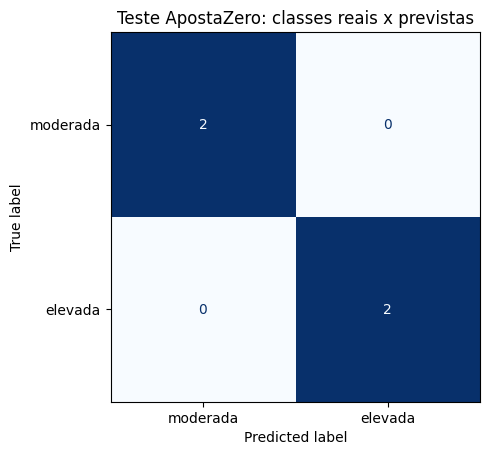

Condições aprendidas pela árvore:
|--- pontuacao_pgsi <= 7.50
|   |--- class: moderada
|--- pontuacao_pgsi >  7.50
|   |--- class: elevada



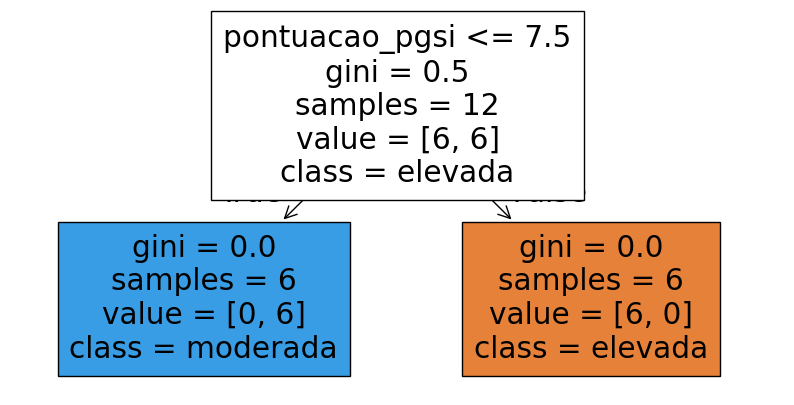

In [4]:
# Inicialização e treinamento da Árvore de Decisão
modelo = DecisionTreeClassifier(max_depth=2, random_state=42)
modelo.fit(X_treino, y_treino)

# Previsões no conjunto de teste
previsoes = modelo.predict(X_teste)

# Avaliação de acurácia
print(f"Acurácia no teste: {accuracy_score(y_teste, previsoes):.1%}")

# Matriz de confusão
classes = ["moderada", "elevada"]
matriz = confusion_matrix(y_teste, previsoes, labels=classes)
print("\nMatriz de Confusão:")
print(pd.DataFrame(matriz, index=classes, columns=classes))

ConfusionMatrixDisplay(matriz, display_labels=classes).plot(
    cmap="Blues", colorbar=False
)
plt.title("Teste ApostaZero: classes reais x previstas")
plt.show()

# Regras aprendidas pelo modelo
print("Condições aprendidas pela árvore:")
print(export_text(modelo, feature_names=list(X.columns)))

# Visualização gráfica da árvore
plt.figure(figsize=(10, 5))
plot_tree(
    modelo,
    feature_names=list(X.columns),
    class_names=list(modelo.classes_),
    filled=True
)
plt.show()

## 5. Base de conhecimento e motor de inferência do ApostaZero

Nesta etapa, a previsão gerada pelo modelo supervisionado (`perfil_vulnerabilidade`) torna-se um **fato** na memória de trabalho do sistema especialista, sendo combinada com o fato `gatilho_ativo` informado pelo usuário no check-in.

**Origem das regras:**
- **R1 e R2:** Fundamentadas na **Terapia Cognitivo-Comportamental (TCC)** aplicada a comportamentos aditivos (automonitoramento preventivo e técnica de *'surfar a fissura'* diante de gatilhos como recebimento de salário ou tédio).
- **R3 e R4:** Fundamentadas na escala **PGSI** (*Problem Gambling Severity Index*, corte $\ge 8$), nos critérios diagnósticos do **DSM-5** para Transtorno do Jogo e nas diretrizes brasileiras de Jogo Responsável (SPA/MF) e acolhimento em crise (**CVV 188**, **CAPS** e **Jogadores Anônimos**).

In [5]:
# Base de conhecimento com 4 regras explícitas SE... ENTÃO...
regras = [
    {
        "id": "R1",
        "perfil_vulnerabilidade": "moderada",
        "gatilho_ativo": False,
        "estado_automato": "VERDE",
        "proximo_checkin": "24 horas",
        "acao": "Manter rotina preventiva, registrar mais um dia sem apostas e acompanhar metas financeiras.",
        "fonte": "TCC - Automonitoramento e reforço positivo."
    },
    {
        "id": "R2",
        "perfil_vulnerabilidade": "moderada",
        "gatilho_ativo": True,
        "estado_automato": "AMARELO",
        "proximo_checkin": "2 horas",
        "acao": "Aplicar técnica de 'surfar a fissura' (aguardar 15 a 30 min) e iniciar atividade de distração longe do celular.",
        "fonte": "TCC - Manejo de gatilhos situacionais imediatos (dia de pagamento ou tédio)."
    },
    {
        "id": "R3",
        "perfil_vulnerabilidade": "elevada",
        "gatilho_ativo": False,
        "estado_automato": "AMARELO",
        "proximo_checkin": "1 hora",
        "acao": "Realizar exercício de respiração guiada, revisar histórico de perdas acumuladas e acionar rede de apoio.",
        "fonte": "Escala PGSI (>= 8 pontos) e DSM-5 - Vigilância intensiva para jogo problemático."
    },
    {
        "id": "R4",
        "perfil_vulnerabilidade": "elevada",
        "gatilho_ativo": True,
        "estado_automato": "VERMELHO",
        "proximo_checkin": "30 minutos",
        "acao": "Protocolo de contenção: ativar autoexclusão nas plataformas de bets, bloquear transferências e buscar apoio (CAPS / Jogadores Anônimos / CVV 188).",
        "fonte": "DSM-5, normas de Jogo Responsável (SPA/MF) e protocolo de crise ApostaZero."
    }
]

# Motor de inferência
def aplicar_regras(perfil_vulnerabilidade, gatilho_ativo):
    for regra in regras:
        if (regra["perfil_vulnerabilidade"] == perfil_vulnerabilidade and
                regra["gatilho_ativo"] == gatilho_ativo):
            return {
                "perfil_previsto": perfil_vulnerabilidade,
                "regra": regra["id"],
                "estado_risco": regra["estado_automato"],
                "proximo_checkin": regra["proximo_checkin"],
                "recomendacao": regra["acao"],
                "explicacao": (
                    f"Perfil previsto pelo classificador: {perfil_vulnerabilidade}; "
                    f"gatilho situacional ativo: {gatilho_ativo}. "
                    f"Base: {regra['fonte']}"
                )
            }
    raise ValueError("Nenhuma regra compatível com os fatos informados.")

## 6. Integrar o modelo ao sistema especialista e testar 3 novos casos

In [6]:
def orientar_usuario_apostazero(vontade, pgsi, gatilho_ativo):
    # Validação de domínio das entradas
    if not 0 <= vontade <= 10:
        raise ValueError("A vontade de apostar deve estar entre 0 e 10.")
    if not 0 <= pgsi <= 27:
        raise ValueError("A pontuação PGSI deve estar entre 0 e 27.")
    if not isinstance(gatilho_ativo, bool):
        raise ValueError("gatilho_ativo deve ser True ou False.")

    novo_caso = pd.DataFrame([{
        "vontade_apostar": vontade,
        "pontuacao_pgsi": pgsi
    }])

    # 1. Previsão via Aprendizado Supervisionado
    perfil = modelo.predict(novo_caso)[0]

    # 2. Inferência via Sistema Especialista
    resultado = aplicar_regras(perfil, gatilho_ativo)

    # 3. Verificação de extrapolação fora do intervalo de treino
    fora = any(
        not X_treino[c].min() <= novo_caso[c].iloc[0] <= X_treino[c].max()
        for c in X.columns
    )
    resultado["aviso"] = (
        "Atenção: entrada fora dos intervalos observados no treino."
        if fora else "Simulação acadêmica; orientação sujeita a revisão humana/profissional."
    )
    return resultado

# Demonstração de 3 casos inéditos (não utilizados no treino)
casos = [
    (2, 3, False),   # Caso 1: Usuário estável e sem gatilho
    (6, 11, True),   # Caso 2: Perfil PGSI problemático + vontade 6 + gatilho (salário/tédio)
    (3, 5, True),    # Caso 3: Vulnerabilidade moderada, mas com gatilho situacional ativo
]

for i, (vontade, pgsi, gatilho) in enumerate(casos, 1):
    print(f"\nCASO {i}: vontade={vontade}/10; PGSI={pgsi}/27; gatilho_ativo={gatilho}")
    for campo, valor in orientar_usuario_apostazero(vontade, pgsi, gatilho).items():
        print(f"  {campo}: {valor}")


CASO 1: vontade=2/10; PGSI=3/27; gatilho_ativo=False
  perfil_previsto: moderada
  regra: R1
  estado_risco: VERDE
  proximo_checkin: 24 horas
  recomendacao: Manter rotina preventiva, registrar mais um dia sem apostas e acompanhar metas financeiras.
  explicacao: Perfil previsto pelo classificador: moderada; gatilho situacional ativo: False. Base: TCC - Automonitoramento e reforço positivo.
  aviso: Simulação acadêmica; orientação sujeita a revisão humana/profissional.

CASO 2: vontade=6/10; PGSI=11/27; gatilho_ativo=True
  perfil_previsto: elevada
  regra: R4
  estado_risco: VERMELHO
  proximo_checkin: 30 minutos
  recomendacao: Protocolo de contenção: ativar autoexclusão nas plataformas de bets, bloquear transferências e buscar apoio (CAPS / Jogadores Anônimos / CVV 188).
  explicacao: Perfil previsto pelo classificador: elevada; gatilho situacional ativo: True. Base: DSM-5, normas de Jogo Responsável (SPA/MF) e protocolo de crise ApostaZero.
  aviso: Simulação acadêmica; orientaçã

## 7. Consulta interativa (Experimente alterar os valores)

In [7]:
# Altere apenas gatilho_ativo (True/False) mantendo vontade e pgsi para observar a mudança de regra

vontade = 0
pgsi = 27
gatilho_ativo = False

resultado = orientar_usuario_apostazero(vontade, pgsi, gatilho_ativo)
for campo, valor in resultado.items():
    print(f"{campo}: {valor}")

perfil_previsto: elevada
regra: R3
estado_risco: AMARELO
proximo_checkin: 1 hora
recomendacao: Realizar exercício de respiração guiada, revisar histórico de perdas acumuladas e acionar rede de apoio.
explicacao: Perfil previsto pelo classificador: elevada; gatilho situacional ativo: False. Base: Escala PGSI (>= 8 pontos) e DSM-5 - Vigilância intensiva para jogo problemático.
aviso: Atenção: entrada fora dos intervalos observados no treino.


## 8. Análise dos Resultados, Limitações e Perguntas de Fechamento

### Discussão sobre erros, limitações e ética
- **Tamanho e representatividade da amostra:** O dataset possui apenas 16 registros simulados e 4 casos de teste. Embora a acurácia no teste tenha sido de **100,0%**, esse resultado não comprova eficácia clínica real, pois as fronteiras entre as classes foram construídas de forma linear e limpa.
- **Exemplos pouco representados e extrapolação:** Valores extremos (como `vontade_apostar = 0` ou `10`, ou `pontuacao_pgsi = 27`) ficam fora do intervalo observado no treino (`[1..9]` e `[1..22]`), disparando o alerta de confiabilidade na função integradora.
- **Privacidade e responsabilidade ética (LGPD e Saúde Mental):** Dados sobre comportamento de apostas e saúde emocional são sensíveis. Em ambiente real, exigem anonimização, consentimento explícito e supervisão humana. O ApostaZero atua exclusivamente como ferramenta educacional e de apoio preventivo, encaminhando casos críticos para atendimento profissional (CAPS, Jogadores Anônimos e CVV 188).

### Respostas às perguntas de análise do roteiro
1. **Qual parte do programa aprende com os dados?**  
   O classificador `DecisionTreeClassifier` do `scikit-learn`, que ajusta seus limiares de decisão (`pontuacao_pgsi` e `vontade_apostar`) a partir dos 12 exemplos de treino.
2. **Qual parte aplica regras humanas?**  
   A base de conhecimento (`regras` R1 a R4) e o motor de inferência (`aplicar_regras`), codificados explicitamente pela equipe com base em PGSI, DSM-5 e TCC.
3. **Por que o fato `gatilho_ativo` não aparece entre os atributos do modelo neste exemplo?**  
   Para demonstrar a arquitetura híbrida: o modelo de Machine Learning estima o padrão basal/estrutural de vulnerabilidade a partir de métricas numéricas, enquanto o sistema especialista incorpora evidências contextuais imediatas do momento do check-in sem precisar retreinar o modelo.
4. **O que acontece ao mudar apenas o fato `gatilho_ativo`?**  
   A previsão do modelo (`perfil_vulnerabilidade`) permanece idêntica, mas o motor de inferência seleciona outra regra (por exemplo, mudando de `R3` no estado `AMARELO` para `R4` no estado `VERMELHO` quando o perfil é `elevada`), alterando o protocolo e reduzindo o intervalo do próximo check-in de 1 hora para 30 minutos.
5. **Um resultado de 100% em quatro casos é suficiente para uso real?**  
   Não. Amostras pequenas produzem métricas otimistas e instáveis. Para uso real seriam necessários dados clínicos validados em maior escala, validação cruzada e auditoria contínua por especialistas da área de saúde.